# Modèle de recommandation de cultures — Entraînement et évaluation


### Sujet
*Conception et réalisation d'un système intelligent d'aide à la décision pour la recommandation de cultures adaptées aux zones agroécologiques du Sénégal*

**Étudiant :** Mohamed Diop

---

### De quoi parle ce notebook ?
Ce notebook entraîne le **cerveau** de l'application : le modèle qui, à partir des
caractéristiques d'une parcelle (sol, climat, végétation), recommande les cultures
les plus adaptées.

### Nature du problème (vocabulaire)
| Question | Réponse |
|---|---|
| Type d'apprentissage ? | **Apprentissage supervisé** (on dispose d'étiquettes : les cultures aptes sont connues) |
| Prédire ou classer ? | **Classer** — la sortie est une catégorie (culture apte / non apte), pas une valeur numérique. Ce n'est donc pas de la régression. |
| Quel type de classification ? | **Multi-étiquettes** (*multi-label*) : une même parcelle peut convenir à plusieurs cultures à la fois. |

### Les données
Jeu de données construit par **fusion de sources ouvertes** sur les 6 zones
agroécologiques du Sénégal (900 points GPS, 150 par zone) :
- **Sol** — ISRIC SoilGrids (250 m) + iSDAsoil Africa (30 m, pour P et K)
- **Climat** — NASA POWER (climatologie 2001-2020)
- **Végétation** — NDVI satellitaire MODIS (Google Earth Engine)
- **Étiquetage** — règles d'aptitude agronomique FAO Ecocrop

---
## 1. Importation des bibliothèques

On utilise **scikit-learn** (bibliothèque de référence en machine learning) et
**XGBoost**. Aucun réseau de neurones : sur des données tabulaires comme les nôtres,
les modèles à base d'arbres et le SVM sont l'état de l'art reconnu et se justifient
mieux qu'un réseau de neurones, plus lourd et moins interprétable ici.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report
from xgboost import XGBClassifier
import joblib

SEED = 42
plt.rcParams["figure.dpi"] = 110

---
## 2. Chargement du jeu de données

Le fichier contient **une ligne par couple (parcelle, culture apte)**. Une même
parcelle apparaît donc sur plusieurs lignes — une par culture qui lui convient.

In [ ]:
df = pd.read_csv("dataset_final_multiclasse.csv")
print(f"Nombre de lignes : {df.shape[0]}")
print(f"Nombre de colonnes : {df.shape[1]}")
df.head()

Nombre de lignes : 5480
Nombre de colonnes : 21


,zone_agroecologique,latitude,longitude,N_total_g_kg,P_extractible_ppm,K_extractible_ppm,pH_eau,clay_pct,sand_pct,silt_pct,...,temperature_moy_C,temperature_max_mois_C,temperature_min_mois_C,humidite_moy_pct,pluie_annuelle_mm,pluie_hivernage_mm,ndvi_moyen_annuel,ndvi_hivernage,culture,score_aptitude
0,Vallee_du_Fleuve,15.6391,-14.8962,0.495,5.0,59.3,6.75,17.9,67.2,15.0,...,28.62,32.9,23.49,39.7,461.4,454.5,0.2886,0.3843,mil,1.000
1,Vallee_du_Fleuve,15.6391,-14.8962,0.495,5.0,59.3,6.75,17.9,67.2,15.0,...,28.62,32.9,23.49,39.7,461.4,454.5,0.2886,0.3843,sorgho,0.931
2,Vallee_du_Fleuve,15.6391,-14.8962,0.495,5.0,59.3,6.75,17.9,67.2,15.0,...,28.62,32.9,23.49,39.7,461.4,454.5,0.2886,0.3843,mais,0.675
3,Vallee_du_Fleuve,15.6391,-14.8962,0.495,5.0,59.3,6.75,17.9,67.2,15.0,...,28.62,32.9,23.49,39.7,461.4,454.5,0.2886,0.3843,riz,1.000
4,Vallee_du_Fleuve,15.6391,-14.8962,0.495,5.0,59.3,6.75,17.9,67.2,15.0,...,28.62,32.9,23.49,39.7,461.4,454.5,0.2886,0.3843,arachide,0.906


In [ ]:
# Combien de cultures ? Combien de parcelles réellement distinctes ?
print("Les 8 cultures étudiées :")
print(df["culture"].value_counts(), "\n")
n_parcelles = len(df[["latitude", "longitude"]].drop_duplicates())
print(f"Parcelles (points GPS) distinctes : {n_parcelles}")
print(f"Valeurs manquantes : {df.isna().sum().sum()}")

Les 8 cultures étudiées :
culture
tomate      802
sorgho      785
niebe       759
mil         707
mais        697
arachide    696
riz         540
manioc      494
Name: count, dtype: int64 

Parcelles (points GPS) distinctes : 824
Valeurs manquantes : 0


---
## 3. Variables d'entrée (inputs) et sortie (output)

### Les 16 variables d'entrée
| Famille | Variables |
|---|---|
| **Sol** (8) | azote N, phosphore P, potassium K, pH, argile, sable, limon, carbone organique |
| **Climat** (6) | température moyenne / max / min, humidité, pluie annuelle, pluie d'hivernage |
| **Végétation** (2) | NDVI moyen annuel, NDVI d'hivernage |

### La sortie
Pour une parcelle, le modèle évalue les **8 cultures** et renvoie pour chacune une
**probabilité d'aptitude**. L'application affichera les **3 meilleures**.

> On **exclut volontairement** `latitude`, `longitude` et `zone_agroecologique`
> des variables d'entrée : le modèle doit apprendre les relations
> *sol/climat → culture*, et non mémoriser la position géographique. C'est ce
> qui lui permettra de généraliser à n'importe quelle nouvelle parcelle.

In [ ]:
FEATURES = ["N_total_g_kg", "P_extractible_ppm", "K_extractible_ppm",
            "pH_eau", "clay_pct", "sand_pct", "silt_pct",
            "carbone_org_g_kg", "temperature_moy_C",
            "temperature_max_mois_C", "temperature_min_mois_C",
            "humidite_moy_pct", "pluie_annuelle_mm", "pluie_hivernage_mm",
            "ndvi_moyen_annuel", "ndvi_hivernage"]
print(f"{len(FEATURES)} variables d'entrée")

16 variables d'entrée


---
## 4. Mise en forme pour la classification multi-étiquettes

On **regroupe** les lignes par parcelle : chaque parcelle devient une seule ligne,
dont la cible est **l'ensemble des cultures aptes**. `MultiLabelBinarizer` transforme
cette liste en un vecteur de 0 et de 1 (une case par culture).

In [ ]:
# 1 ligne par parcelle, cible = liste des cultures aptes
grp = (df.groupby(["latitude", "longitude"])
         .agg({**{f: "first" for f in FEATURES},
               "culture": lambda s: sorted(set(s))})
         .reset_index())

mlb = MultiLabelBinarizer()
Y = mlb.fit_transform(grp["culture"])   # matrice binaire (parcelles x 8 cultures)
X = grp[FEATURES].values                # matrice des variables d'entrée
classes = list(mlb.classes_)

print(f"X : {X.shape}  (parcelles x variables)")
print(f"Y : {Y.shape}  (parcelles x cultures)")
print(f"Cultures : {classes}")
print(f"Nombre moyen de cultures aptes par parcelle : {Y.sum(axis=1).mean():.1f}")

X : (824, 16)  (parcelles x variables)
Y : (824, 8)  (parcelles x cultures)
Cultures : ['arachide', 'mais', 'manioc', 'mil', 'niebe', 'riz', 'sorgho', 'tomate']
Nombre moyen de cultures aptes par parcelle : 6.7


---
## 5. Séparation entraînement / test

Règle d'or du machine learning : on **n'évalue jamais** un modèle sur les données
qui ont servi à l'entraîner. On réserve donc 20 % des parcelles pour un test final,
que le modèle ne verra pas pendant l'apprentissage.

In [ ]:
X_tr, X_te, Y_tr, Y_te = train_test_split(
    X, Y, test_size=0.2, random_state=SEED)
print(f"Entraînement : {len(X_tr)} parcelles")
print(f"Test (jamais vues) : {len(X_te)} parcelles")

Entraînement : 659 parcelles
Test (jamais vues) : 165 parcelles


---
## 6. Les modèles comparés et les métriques

### Trois modèles
- **SVM (machine à vecteurs de support)**, noyau RBF — modèle de référence en classification
- **Random Forest (forêt aléatoire)** — ensemble de 300 arbres de décision
- **XGBoost** — arbres construits séquentiellement, très performant sur données tabulaires

Chaque modèle est mis en **stratégie One-vs-Rest** (un classifieur binaire par culture)
et précédé d'une **standardisation** des variables (`StandardScaler`), indispensable
pour le SVM.

### Comment mesure-t-on la qualité ?
- **F1-score** : moyenne équilibrée entre précision et rappel (entre 0 et 1, plus c'est haut mieux c'est)
- **Validation croisée 5-fold** : on entraîne 5 fois sur des découpages différents pour vérifier que le résultat est stable et non un coup de chance
- **Précision@3** : parmi les 3 cultures les mieux notées, quelle proportion est réellement apte ? → c'est la **métrique métier**, car l'application affiche un top-3

In [ ]:
def precision_at_k(Y_vrai, scores, k=3):
    """Parmi les k cultures les mieux notées, proportion réellement apte."""
    idx = np.argsort(-scores, axis=1)[:, :k]
    return np.take_along_axis(Y_vrai, idx, axis=1).mean()

def scores_proba(modele, X):
    """Probabilité d'aptitude prédite pour chacune des 8 cultures."""
    X_std = modele.named_steps["scaler"].transform(X)
    return np.column_stack([est.predict_proba(X_std)[:, 1]
                            for est in modele.named_steps["clf"].estimators_])

def pipeline(clf):
    return Pipeline([("scaler", StandardScaler()),
                     ("clf", OneVsRestClassifier(clf, n_jobs=-1))])

---
## 7. Entraînement et comparaison

Pour chaque modèle : validation croisée 5-fold sur l'entraînement, puis évaluation
finale sur les 20 % de parcelles réservées.

In [ ]:
modeles = {
    "SVM (RBF, C=10)": pipeline(SVC(kernel="rbf", C=10, gamma="scale",
                                    probability=True, random_state=SEED)),
    "Random Forest": pipeline(RandomForestClassifier(n_estimators=300,
                                                     random_state=SEED)),
    "XGBoost": pipeline(XGBClassifier(n_estimators=300, max_depth=5,
                                      learning_rate=0.1, random_state=SEED,
                                      eval_metric="logloss")),
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
resultats = []
for nom, pipe in modeles.items():
    f1_cv = []
    for i_tr, i_va in cv.split(X_tr):
        pipe.fit(X_tr[i_tr], Y_tr[i_tr])
        s = scores_proba(pipe, X_tr[i_va])
        f1_cv.append(f1_score(Y_tr[i_va], (s >= 0.5).astype(int),
                              average="micro", zero_division=0))
    pipe.fit(X_tr, Y_tr)
    s_te = scores_proba(pipe, X_te)
    Y_pred = (s_te >= 0.5).astype(int)
    resultats.append({
        "Modèle": nom,
        "F1 (validation croisée)": round(float(np.mean(f1_cv)), 4),
        "F1-micro (test)": round(float(f1_score(Y_te, Y_pred,
                                    average="micro", zero_division=0)), 4),
        "F1-macro (test)": round(float(f1_score(Y_te, Y_pred,
                                    average="macro", zero_division=0)), 4),
        "Précision@3 (test)": round(float(precision_at_k(Y_te, s_te, 3)), 4),
    })

tableau = pd.DataFrame(resultats).sort_values("F1-micro (test)",
                                              ascending=False).reset_index(drop=True)
print("TABLEAU COMPARATIF DES MODÈLES\n")
tableau

TABLEAU COMPARATIF DES MODÈLES



,Modèle,F1 (validation croisée),F1-micro (test),F1-macro (test),Précision@3 (test)
0,Random Forest,0.9927,0.9917,0.9906,1.000
1,XGBoost,0.9916,0.9889,0.9875,1.000
2,"SVM (RBF, C=10)",0.9893,0.9885,0.9876,0.998


**Lecture du tableau :** les trois modèles obtiennent des scores très élevés et
proches. La **Précision@3** proche de 1 signifie que les 3 cultures recommandées
sont presque toujours réellement adaptées — c'est le résultat clé pour l'application.

---
## 8. Analyse détaillée du meilleur modèle

On regarde la performance **culture par culture** : le modèle est-il aussi bon pour
toutes les cultures, ou en rate-t-il certaines ?

In [ ]:
meilleur_nom = tableau.iloc[0]["Modèle"]
meilleur = modeles[meilleur_nom]
print(f"Meilleur modèle : {meilleur_nom}\n")

s_te = scores_proba(meilleur, X_te)
Y_pred = (s_te >= 0.5).astype(int)
print(classification_report(Y_te, Y_pred, target_names=classes,
                            zero_division=0))

Meilleur modèle : Random Forest

              precision    recall  f1-score   support

    arachide       1.00      1.00      1.00       137
        mais       1.00      1.00      1.00       137
      manioc       1.00      1.00      1.00        99
         mil       1.00      1.00      1.00       137
       niebe       1.00      1.00      1.00       149
         riz       0.94      0.94      0.94       109
      sorgho       1.00      1.00      1.00       157
      tomate       0.98      0.99      0.98       159

   micro avg       0.99      0.99      0.99      1084
   macro avg       0.99      0.99      0.99      1084
weighted avg       0.99      0.99      0.99      1084
 samples avg       0.99      0.99      0.99      1084



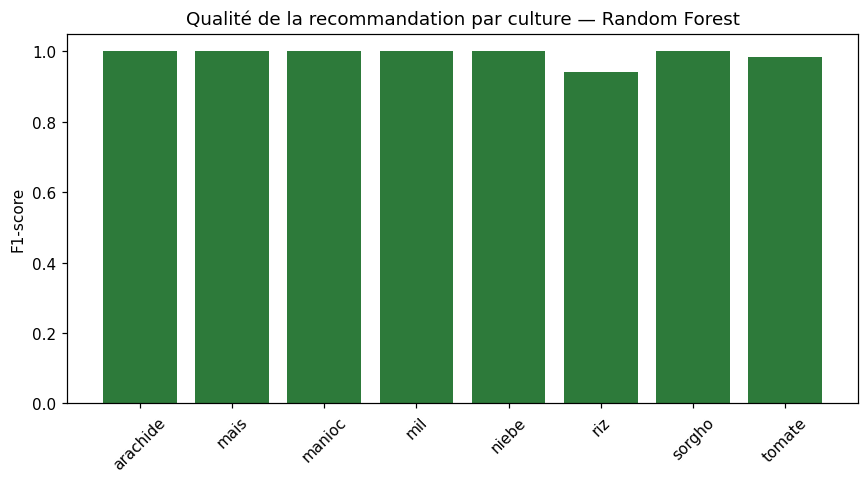

In [ ]:
f1_cult = f1_score(Y_te, Y_pred, average=None, zero_division=0)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(classes, f1_cult, color="#2d7a3a")
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1-score")
ax.set_title(f"Qualité de la recommandation par culture — {meilleur_nom}")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

---
## 9. Quelles variables comptent le plus ?

L'**importance des variables** révèle sur quels critères le modèle s'appuie pour
décider. C'est essentiel pour l'interprétation agronomique et pour justifier
l'ajout des données satellitaires (NDVI).

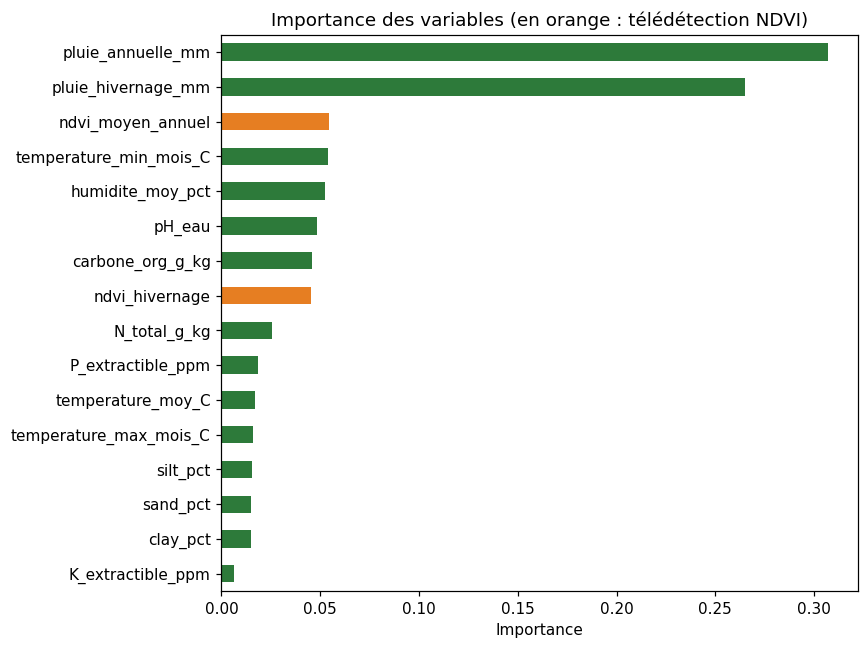

Classement :
   1. pluie_annuelle_mm        0.3069
   2. pluie_hivernage_mm       0.2649
   3. ndvi_moyen_annuel        0.0547
   4. temperature_min_mois_C   0.0542
   5. humidite_moy_pct         0.0522
   6. pH_eau                   0.0482
   7. carbone_org_g_kg         0.0460
   8. ndvi_hivernage           0.0452
   9. N_total_g_kg             0.0254
  10. P_extractible_ppm        0.0184
  11. temperature_moy_C        0.0168
  12. temperature_max_mois_C   0.0159
  13. silt_pct                 0.0153
  14. sand_pct                 0.0149
  15. clay_pct                 0.0148
  16. K_extractible_ppm        0.0064


In [ ]:
rf = RandomForestClassifier(n_estimators=300, random_state=SEED)
ovr = OneVsRestClassifier(rf).fit(StandardScaler().fit_transform(X), Y)
imp = pd.Series(np.mean([e.feature_importances_ for e in ovr.estimators_], axis=0),
                index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
couleurs = ["#e67e22" if "ndvi" in v else "#2d7a3a" for v in imp.index]
imp.plot.barh(ax=ax, color=couleurs)
ax.set_title("Importance des variables (en orange : télédétection NDVI)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

print("Classement :")
for i, (k, v) in enumerate(imp.sort_values(ascending=False).items(), 1):
    print(f"  {i:2}. {k:<24} {v:.4f}")

**Interprétation :** la pluviométrie domine, ce qui est cohérent avec le contexte
sahélien où l'eau est le facteur limitant. Les indices **NDVI** se classent parmi les
variables les plus importantes, confirmant que l'information satellitaire apporte une
contribution réelle, indépendante des règles agronomiques d'étiquetage.

---
## 10. Exemple concret de recommandation

Simulation de ce que fera l'application : on prend une parcelle du jeu de test et
on affiche les 3 cultures recommandées avec leur probabilité.

In [ ]:
i = 7
parcelle = X_te[i:i+1]
probas = scores_proba(meilleur, parcelle)[0]
top3 = np.argsort(-probas)[:3]

print("Caractéristiques de la parcelle :")
for f, v in zip(FEATURES, parcelle[0]):
    print(f"   {f:<24} {v:.2f}")
print("\n>>> TOP 3 DES CULTURES RECOMMANDÉES :")
for rang, j in enumerate(top3, 1):
    print(f"   {rang}. {classes[j]:<10} — aptitude {probas[j]*100:.0f}%")
reel = [classes[j] for j in np.where(Y_te[i] == 1)[0]]
print(f"\nCultures réellement aptes (vérité terrain) : {reel}")

Caractéristiques de la parcelle :
   N_total_g_kg             1.90
   P_extractible_ppm        6.40
   K_extractible_ppm        53.60
   pH_eau                   5.55
   clay_pct                 32.00
   sand_pct                 38.20
   silt_pct                 29.90
   carbone_org_g_kg         23.35
   temperature_moy_C        27.03
   temperature_max_mois_C   31.07
   temperature_min_mois_C   23.21
   humidite_moy_pct         60.71
   pluie_annuelle_mm        1129.20
   pluie_hivernage_mm       1110.80
   ndvi_moyen_annuel        0.58
   ndvi_hivernage           0.69

>>> TOP 3 DES CULTURES RECOMMANDÉES :
   1. mais       — aptitude 100%
   2. manioc     — aptitude 100%
   3. sorgho     — aptitude 100%

Cultures réellement aptes (vérité terrain) : ['arachide', 'mais', 'manioc', 'mil', 'niebe', 'riz', 'sorgho', 'tomate']


---
## 11. Sauvegarde du modèle pour l'application

Le modèle final est ré-entraîné sur **100 % des données**, puis sauvegardé dans un
fichier `.joblib`. C'est ce fichier que l'API (FastAPI) chargera pour répondre aux
requêtes de l'application mobile.

In [ ]:
meilleur.fit(X, Y)
joblib.dump({"pipeline": meilleur, "binarizer": mlb, "features": FEATURES},
            "modele_final.joblib")
print("Modèle sauvegardé : modele_final.joblib")
print("Prêt à être déployé dans l'API de l'application.")

Modèle sauvegardé : modele_final.joblib
Prêt à être déployé dans l'API de l'application.


---
## 12. Conclusion et limites

### Ce qui a été réalisé
- Un jeu de données original pour le Sénégal (900 parcelles, 6 zones, 16 variables)
- Un modèle de **classification multi-étiquettes** recommandant, pour toute parcelle,
  les cultures adaptées parmi 8, avec une **Précision@3 proche de 1**

### Limite à assumer
Les étiquettes d'aptitude ont été dérivées de **règles agronomiques** (FAO Ecocrop).
Le modèle apprend donc à généraliser ces règles sous une forme continue et déployable
(**modèle de substitution**). Les scores élevés reflètent la cohérence de ce cadre.

### Perspectives
1. **Pondérer les étiquettes par les rendements réels** (ANSD/FAOSTAT) pour ancrer le
   modèle dans des observations de terrain.
2. Enrichir encore les variables satellitaires (séries temporelles de NDVI).
3. Étendre à d'autres cultures et affiner la résolution spatiale des zones.